# Tutorial 4 — Foundation models and fine-tuning

*Part 2 — Data and training · tutorial 4 of 9 · previous: [03 Training an X-MACE model](03_training.ipynb) · next: [05 Using a trained model](05_using_a_trained_model.ipynb)*

Ground-state foundation models (MACE-OFF, MACE-MP, MACE-OMOL, MACE-MH-1,
MACE-POLAR-1) have learned chemistry from millions of structures. X-MACE can start
from any of them: the foundation becomes the **backbone** and every electronic state
starts on its ground-state surface. This tutorial is a collection of **complete
`mace_run_train` commands**:

1. one per foundation model, on the same small SO2 data set;
2. one per fine-tuning strategy: frozen layers, smaller backbone learning rate,
   LoRA, multi-head fine-tuning with replay and pseudolabels, an extra ground-state
   head, the autoencoder, state-specific electrostatics;
3. fine-tuning a model you already trained on additional data, and transferring it
   to new states;
4. the same commands on several GPUs and with SLURM.

Every command runs in a `%%bash` cell exactly as you would type it in a terminal
(from `tutorials/xmace/work/foundations`); copy them into your own scripts. All of
them are also in `04_commands.sh` next to this notebook.

**Requirements:** `work/so2_train.xyz` and `work/so2_test.xyz` from Tutorial 2;
internet access for the first download of each foundation model (cached in
`~/.cache/mace`). Runtime: about an hour on 2 CPU cores; on a GPU, set
`DEVICE=cuda` in the first cell and it takes a few minutes.

In [1]:
import os
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

import ase.io
import numpy as np

TUTORIAL = Path.cwd()
WORK = TUTORIAL / "work"
RUN = WORK / "foundations"
RUN.mkdir(parents=True, exist_ok=True)
os.environ["DEVICE"] = "cpu"  # used by the commands below: cpu or cuda
assert (WORK / "so2_train.xyz").exists(), "run Tutorial 2 first"

## 1. The data

Foundation models matter most when data are scarce: we fine-tune on **120** frames
of the SO2 training set and test on the 150 test frames of Tutorial 2. A few more
files for later sections are written here as well: 240 additional frames, replay
geometries, ground-state-only data and a singlets-only data set.

In [2]:
frames = ase.io.read(WORK / "so2_train.xyz", ":")
rng = np.random.default_rng(0)
order = rng.permutation(len(frames))
small = [frames[i] for i in order[:120]]
extra = [frames[i] for i in order[120:360]]
ase.io.write(RUN / "small.xyz", small)                   # 120 frames to fine-tune on
ase.io.write(RUN / "small_plus_extra.xyz", small + extra)  # section 5: more data

# replay geometries for multi-head fine-tuning (labelled by the foundation itself)
replay = []
for atoms in frames[400:600]:
    distorted = ase.Atoms(atoms.get_chemical_symbols(), positions=atoms.positions)
    distorted.positions += rng.normal(scale=0.05, size=distorted.positions.shape)
    replay.append(distorted)
for formula, d in (("SO", 1.48), ("O2", 1.21), ("S2", 1.89)):
    for scale in np.linspace(0.9, 1.2, 8):
        replay.append(ase.Atoms(formula, positions=[[0, 0, 0], [0, 0, d * scale]]))
for atoms in replay:  # placeholders, replaced by the foundation's predictions
    atoms.info["REF_energy"] = 0.0
    atoms.arrays["REF_forces"] = np.zeros((len(atoms), 3))
ase.io.write(RUN / "replay.xyz", replay)

# ground-state data (S0 energy and forces only), e.g. from another method
ground = []
for atoms in frames[400:600]:
    g = ase.Atoms(atoms.get_chemical_symbols(), positions=atoms.positions)
    g.info["REF_energy"] = float(atoms.info["REF_energy"][0])
    g.arrays["REF_forces"] = np.asarray(atoms.info["REF_forces"])[:, 0]
    ground.append(g)
ase.io.write(RUN / "ground.xyz", ground)

# singlets only (4 singlets, their 6 NACs and dipoles), for the transfer in section 5
singlets = []
for atoms in extra:
    s = ase.Atoms(atoms.get_chemical_symbols(), positions=atoms.positions)
    s.info["REF_energy"] = atoms.info["REF_energy"][:4]
    s.info["REF_forces"] = atoms.info["REF_forces"][:, :4]
    s.info["REF_nacs"] = atoms.info["REF_nacs"][:, :6]          # singlet pairs come first
    s.info["REF_dipoles"] = np.concatenate(
        [atoms.info["REF_dipoles"][:4], atoms.info["REF_dipoles"][7:13]]
    )
    singlets.append(s)
ase.io.write(RUN / "singlets.xyz", singlets)
print("written:", sorted(p.name for p in RUN.glob("*.xyz")))

written: ['ground.xyz', 'replay.xyz', 'singlets.xyz', 'small.xyz', 'small_plus_extra.xyz']


## 2. The baseline: training from scratch

The options are those of Tutorial 3: 4 singlets + 3 triplets, NACs, spin–orbit
couplings and dipoles, 15 epochs. The last lines print the error table on the test
set that `mace_run_train` writes at the end of every run.

In [3]:
%%bash
cd work/foundations
mace_run_train \
    --name=scratch \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --r_max=5.0 --hidden_irreps="32x0e + 32x1o" --MLP_irreps=16x0e \
    --num_interactions=2 --correlation=2 \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > scratch.out 2>&1
grep -A5 "Error-table on TEST" logs/scratch_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       9

9.2  |          33.1      |        229.7    |       9.15  |       484.26     |      6010.66     |   

       32.99      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


## 3. One command per foundation model

Add `--foundation_model=...` and leave out the architecture options
(`--r_max`, `--hidden_irreps`, `--num_interactions`, ...): they come from the
foundation. What happens:

| part | from the foundation? | role |
|---|---|---|
| **backbone** (embedding, interactions, products, its readout, E0s, ZBL, electrostatics) | yes — all weights | ground-state energy E₀(R) and atomic features |
| **adapter layer** (one MACE interaction with l = 1 features) | new | equivariant features for NACs, SOCs, dipoles — also for scalar-only foundations |
| **state readouts** | new; energy readouts start at zero | E_s(R) = E₀(R) + correction_s(R) + n_atoms·shift_s, and the couplings |

Before training every state *is* the foundation's ground state (plus a constant
shift per state fitted to the data); training learns the differences.

| model | `--foundation_model` | trained on | elements |
|---|---|---|---|
| MACE-OFF23 | `small_off`, `medium_off`, `large_off` | organic molecules (ωB97M-D3) | H C N O F P S Cl Br I |
| MACE-MP-0 / MPA-0 / OMAT-0 / MATPES | `small`, `medium`, `medium-mpa-0`, `small-omat-0`, `mace-matpes-pbe-0`, ... | inorganic materials (PBE, r²SCAN) | 89 |
| MACE-OMOL-0 | `mace_omol` | OMol25 molecules, charges and spins (ωB97M-V) | 83 |
| MACE-MH-1 | `mh-1` with `--foundation_head=omol` (or `spice_wB97M`, `omat_pbe`, `mp_pbe_refit_add`, `matpes_r2scan`, `oc20_usemppbe`) | six data sets, one head each | 89 |
| MACE-POLAR-1 | `polar-1-s`, `polar-1-m`, `polar-1-l` | molecules with long-range electrostatics | 83 |
| your own | `/path/to/model.model` | any MACE model, or a trained X-MACE model (section 5) | its own |

### MACE-OFF23

In [4]:
%%bash
cd work/foundations
mace_run_train \
    --name=mace_off_small \
    --foundation_model=small_off \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > mace_off_small.out 2>&1
grep -A5 "Error-table on TEST" logs/mace_off_small_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       3

9.9  |          13.3      |        198.9    |       7.92  |       464.56     |      6690.60     |   

       32.48      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### MACE-MP-0 (and MPA-0, OMAT-0, MATPES)

For the Materials Project models MACE switches on multi-head fine-tuning with
downloaded MP replay data by default. `--multiheads_finetuning=False` gives plain
fine-tuning, as for the other models here (section 4 shows replay). The other
materials foundations only differ in the name: `--foundation_model=medium-mpa-0`,
`small-omat-0`, `mace-matpes-pbe-0`, ...

In [5]:
%%bash
cd work/foundations
mace_run_train \
    --name=mace_mp_small \
    --foundation_model=small --multiheads_finetuning=False \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > mace_mp_small.out 2>&1
grep -A5 "Error-table on TEST" logs/mace_mp_small_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       7

5.2  |          25.1      |        212.5    |       8.47  |       516.44     |      7636.85     |   

       41.56      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### MACE-MH-1

MH-1 has six heads, one per data set it was trained on; `--foundation_head` picks
the one whose chemistry and level of theory fit yours (`omol` for molecules). It is
a large model (6 million parameters): use a smaller learning rate than for the
small foundations.

In [6]:
%%bash
cd work/foundations
mace_run_train \
    --name=mace_mh1_omol \
    --foundation_model=mh-1 --foundation_head=omol \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.001 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > mace_mh1_omol.out 2>&1
grep -A5 "Error-table on TEST" logs/mace_mh1_omol_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |      13

2.8  |          44.3      |        176.6    |       7.03  |       628.67     |      7725.76     |   

       42.47      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### MACE-POLAR-1

A foundation with long-range electrostatics. `--excited_long_range=shared` (the
default) gives every state the foundation's electrostatics; section 4 uses `state`.

In [7]:
%%bash
cd work/foundations
mace_run_train \
    --name=mace_polar_1_s \
    --foundation_model=polar-1-s \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average --excited_long_range=shared \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > mace_polar_1_s.out 2>&1
grep -A5 "Error-table on TEST" logs/mace_polar_1_s_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       7

6.3  |          25.4      |        181.7    |       7.24  |       465.70     |      6343.90     |   

       33.66      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### MACE-OMOL

The same pattern; not run here because its extra-large model is slow on CPUs. It
embeds the molecular charge and spin: put them into `atoms.info["total_charge"]` and
`atoms.info["total_spin"]` of your data (0 if absent).

```bash
mace_run_train \
    --name=mace_omol \
    --foundation_model=mace_omol \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.001 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=cuda --default_dtype=float32
```

## 4. One command per fine-tuning strategy

All on MACE-OFF23 small: each command is the MACE-OFF command of section 3 plus the
options of the strategy (see the table).

| strategy | options | idea |
|---|---|---|
| full fine-tuning | — | everything trains (section 3) |
| frozen layers | `--freeze=N` | freeze the backbone's first parts: N ≥ 1 embedding, ≥ 5 interactions, ≥ 6 products, ≥ 7 its readouts; adapter and state readouts always train |
| smaller backbone learning rate | `--lr_params_factors='{...}'` | backbone groups get lr × factor, the new parts the full lr |
| LoRA | `--lora=True --lora_rank=r --lora_alpha=a` | the backbone is frozen and learns a low-rank update, merged at the end |
| multi-head with replay | `--multiheads_finetuning=True --pt_train_file=...` | a `pt_head` keeps the foundation's ground state on replay data |
| replay with pseudolabels | `+ --pseudolabel_replay=True` | the replay data are labelled by the foundation itself |
| extra ground-state head | `--heads=...` (here from a YAML config) | ground-state data as an additional head |
| autoencoder | `--model=AutoencoderExcitedMACE` | ordered states, smooth crossings (Tutorial 9) |
| state-specific electrostatics | `--excited_long_range=state` (MACE-POLAR-1, MACELES) | every state its own atomic charges |

### Frozen layers

In [8]:
%%bash
cd work/foundations
mace_run_train \
    --name=off_freeze \
    --foundation_model=small_off \
    --freeze=5 \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_freeze.out 2>&1
grep "Parameters:" logs/off_freeze_run-1.log | cut -d" " -f4-
grep -A5 "Error-table on TEST" logs/off_freeze_run-1.log | tail -n 5

Parameters: 380784 in total, 129712 trainable


+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |      11

4.5  |          38.2      |        184.3    |       7.34  |       415.10     |      6100.21     |   

       28.19      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### A smaller learning rate for the backbone

In [9]:
%%bash
cd work/foundations
mace_run_train \
    --name=off_backbone_lr \
    --foundation_model=small_off \
    --lr_params_factors='{"embedding_lr_factor": 0.1, "interactions_lr_factor": 0.1, "products_lr_factor": 0.1, "readouts_lr_factor": 0.1}' \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_backbone_lr.out 2>&1
grep -A5 "Error-table on TEST" logs/off_backbone_lr_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       9

0.6  |          30.2      |        191.9    |       7.64  |       484.53     |      6668.24     |   

       26.23      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### LoRA

In [10]:
%%bash
cd work/foundations
mace_run_train \
    --name=off_lora \
    --foundation_model=small_off \
    --lora=True --lora_rank=4 --lora_alpha=1 \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_lora.out 2>&1
grep "LoRA" logs/off_lora_run-1.log | cut -d" " -f4- | head -3
grep -A5 "Error-table on TEST" logs/off_lora_run-1.log | tail -n 5

Injecting LoRA layers with rank=4 and alpha=1.0
Model with LoRA has 397504 trainable parameters.
Mer

ging LoRA weights into base model


+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |      20

1.6  |          67.2      |        215.2    |       8.57  |       430.51     |      6118.38     |   

       24.32      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### Multi-head fine-tuning with replay and pseudolabels

With few excited-state data, fine-tuning can make the backbone forget what made it
general. `--multiheads_finetuning=True` adds a ground-state head `pt_head`, trained
on replay data alongside your data. `--pseudolabel_replay=True` labels the replay
data with the foundation itself, so any geometries will do (here distorted SO2 and
SO, O2, S2 fragments). `--E0s=foundation` keeps one energy reference for both heads;
`--force_mh_ft_lr=True` keeps our learning rate (MACE otherwise switches to
lr 1e-4 and EMA 0.99999, settings meant for long runs).

In [11]:
%%bash
cd work/foundations
mace_run_train \
    --name=off_replay \
    --foundation_model=small_off \
    --multiheads_finetuning=True --pt_train_file=replay.xyz \
    --pseudolabel_replay=True --weight_pt_head=1.0 --force_mh_ft_lr=True \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=foundation \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_replay.out 2>&1
grep "Using heads\|pseudolabels to" logs/off_replay_run-1.log | cut -d" " -f4-
grep -A5 "Error-table on TEST" logs/off_replay_run-1.log | tail -n 5

Using heads: ['Default', 'pt_head']
Applying pseudolabels to pt_head configurations using foundation

 model
Successfully applied pseudolabels to 191 training configurations
Successfully applied pseudol

abels to 33 validation configurations
Successfully applied pseudolabels to pt_head configurations


+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       9

0.7  |          30.2      |        213.8    |       8.52  |       355.44     |      5291.31     |   

       22.59      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### An extra ground-state head, from a YAML config file

Several heads are easiest to write in a YAML file passed with `--config` (any
option can go there; command-line options still work alongside). Each head names its
own files and says what it predicts: `ground_state: true` is one state, energies and
forces only.

In [12]:
%%bash
cd work/foundations
cat > heads.yaml <<'EOF'
heads:
  excited:
    train_file: small.xyz
    valid_fraction: 0.15
    test_file: ../so2_test.xyz
  ground:
    train_file: ground.xyz
    valid_fraction: 0.15
    ground_state: true
EOF
mace_run_train \
    --name=off_ground_head \
    --config=heads.yaml \
    --foundation_model=small_off \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_ground_head.out 2>&1
grep "Head excited:\|Head ground:" logs/off_ground_head_run-1.log | cut -d" " -f4- | sort -u
grep -A5 "Error-table on TEST" logs/off_ground_head_run-1.log | tail -n 5

Head excited: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors (spin_orbit)

, dipoles=16
Head excited: 7 states (4 singlets, 3 triplets), NACs=9 (raw), SOCs=15 coupling vectors

 (spin_orbit), dipoles=16; interaction energy scale 3.9651, shift per state -1.2248, -0.0504, 0.1751

, 1.3493, -0.2618, -0.0570, 0.0695
Head ground: ground state (energy and forces)
Head ground: ground

 state (energy and forces); interaction energy scale 3.3119, shift per state -0.0053


+-------------------------+-------------+--------------------+-----------------+-------------+------

... (3 outputs left out)

---+------------------+------------------+---------------------+
| excited_Default_excited |       6

6.8  |          22.3      |        197.6    |       7.87  |       362.76     |      5314.71     |   

       20.39      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### The autoencoder model on a foundation

In [13]:
%%bash
cd work/foundations
mace_run_train \
    --name=off_autoencoder \
    --foundation_model=small_off \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=AutoencoderExcitedMACE --num_permutational_invariant=16 \
    --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > off_autoencoder.out 2>&1
grep -A5 "Error-table on TEST" logs/off_autoencoder_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |      27

7.5  |          92.5      |        267.9    |      10.67  |       519.47     |      8303.36     |   

       27.81      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


### State-specific electrostatics with MACE-POLAR-1

With `state`, every state gets its own atomic charges (summing to the molecule's
charge), so the electrostatic energy differs between states — the physics of
charge-transfer excitations. SO2 has none, so it behaves like `shared` here.

In [14]:
%%bash
cd work/foundations
mace_run_train \
    --name=polar_state \
    --foundation_model=polar-1-s \
    --excited_long_range=state --excited_charge_smearing=1.0 \
    --train_file=small.xyz --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=15 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > polar_state.out 2>&1
grep -A5 "Error-table on TEST" logs/polar_state_run-1.log | tail -n 5

+-------------------------+-------------+--------------------+-----------------+-------------+------

------------+------------------+---------------------+
|       config_type       | MAE E / meV | MAE

 E / meV / atom | MAE F / meV / A | rel F MAE % | MAE NACs (x1e-3) | MAE SOCs (x1e-3) | MAE dipoles 

(x1e-3) |
+-------------------------+-------------+--------------------+-----------------+----------

---+------------------+------------------+---------------------+
| Default_Default_Default |       7

5.5  |          25.2      |        198.9    |       7.92  |       401.87     |      5433.52     |   

       27.34      |
+-------------------------+-------------+--------------------+-----------------+

-------------+------------------+------------------+---------------------+


## Comparing the runs

The error tables above are MACE's own. For a fair comparison of all runs we
evaluate every model on the test set with the same phase-consistent comparison as
in Tutorial 3 (energies and forces of all states, smooth NACs, SOC matrix elements,
dipoles; couplings sign-aligned per pair).

             run |  E meV | F meV/Å |   NAC |   SOC |    dip | trainable
         scratch |   99.2 |   229.7 | 0.484 |  8.29 | 0.0330 |    142992
  mace_off_small |   39.9 |   198.9 | 0.465 |  9.26 | 0.0325 |    380784
   mace_mp_small |   75.2 |   212.5 | 0.516 | 10.57 | 0.0416 |    463504
   mace_mh1_omol |  132.8 |   176.6 | 0.629 | 10.68 | 0.0425 |   6382486
  mace_polar_1_s |   76.3 |   181.7 | 0.466 |  8.78 | 0.0337 |   7972094
      off_freeze |  114.5 |   184.3 | 0.415 |  8.44 | 0.0282 |    129712
 off_backbone_lr |   90.6 |   191.9 | 0.485 |  9.23 | 0.0262 |    380784
        off_lora |  201.6 |   215.2 | 0.431 |  8.47 | 0.0243 |    397504
      off_replay |   90.7 |   213.8 | 0.355 |  7.32 | 0.0226 |    382672
 off_ground_head |   66.8 |   197.6 | 0.363 |  7.35 | 0.0204 |    382672
 off_autoencoder |  277.5 |   267.9 | 0.519 | 11.50 | 0.0278 |    437884
     polar_state |   75.5 |   198.9 | 0.402 |  7.51 | 0.0273 |   7976814


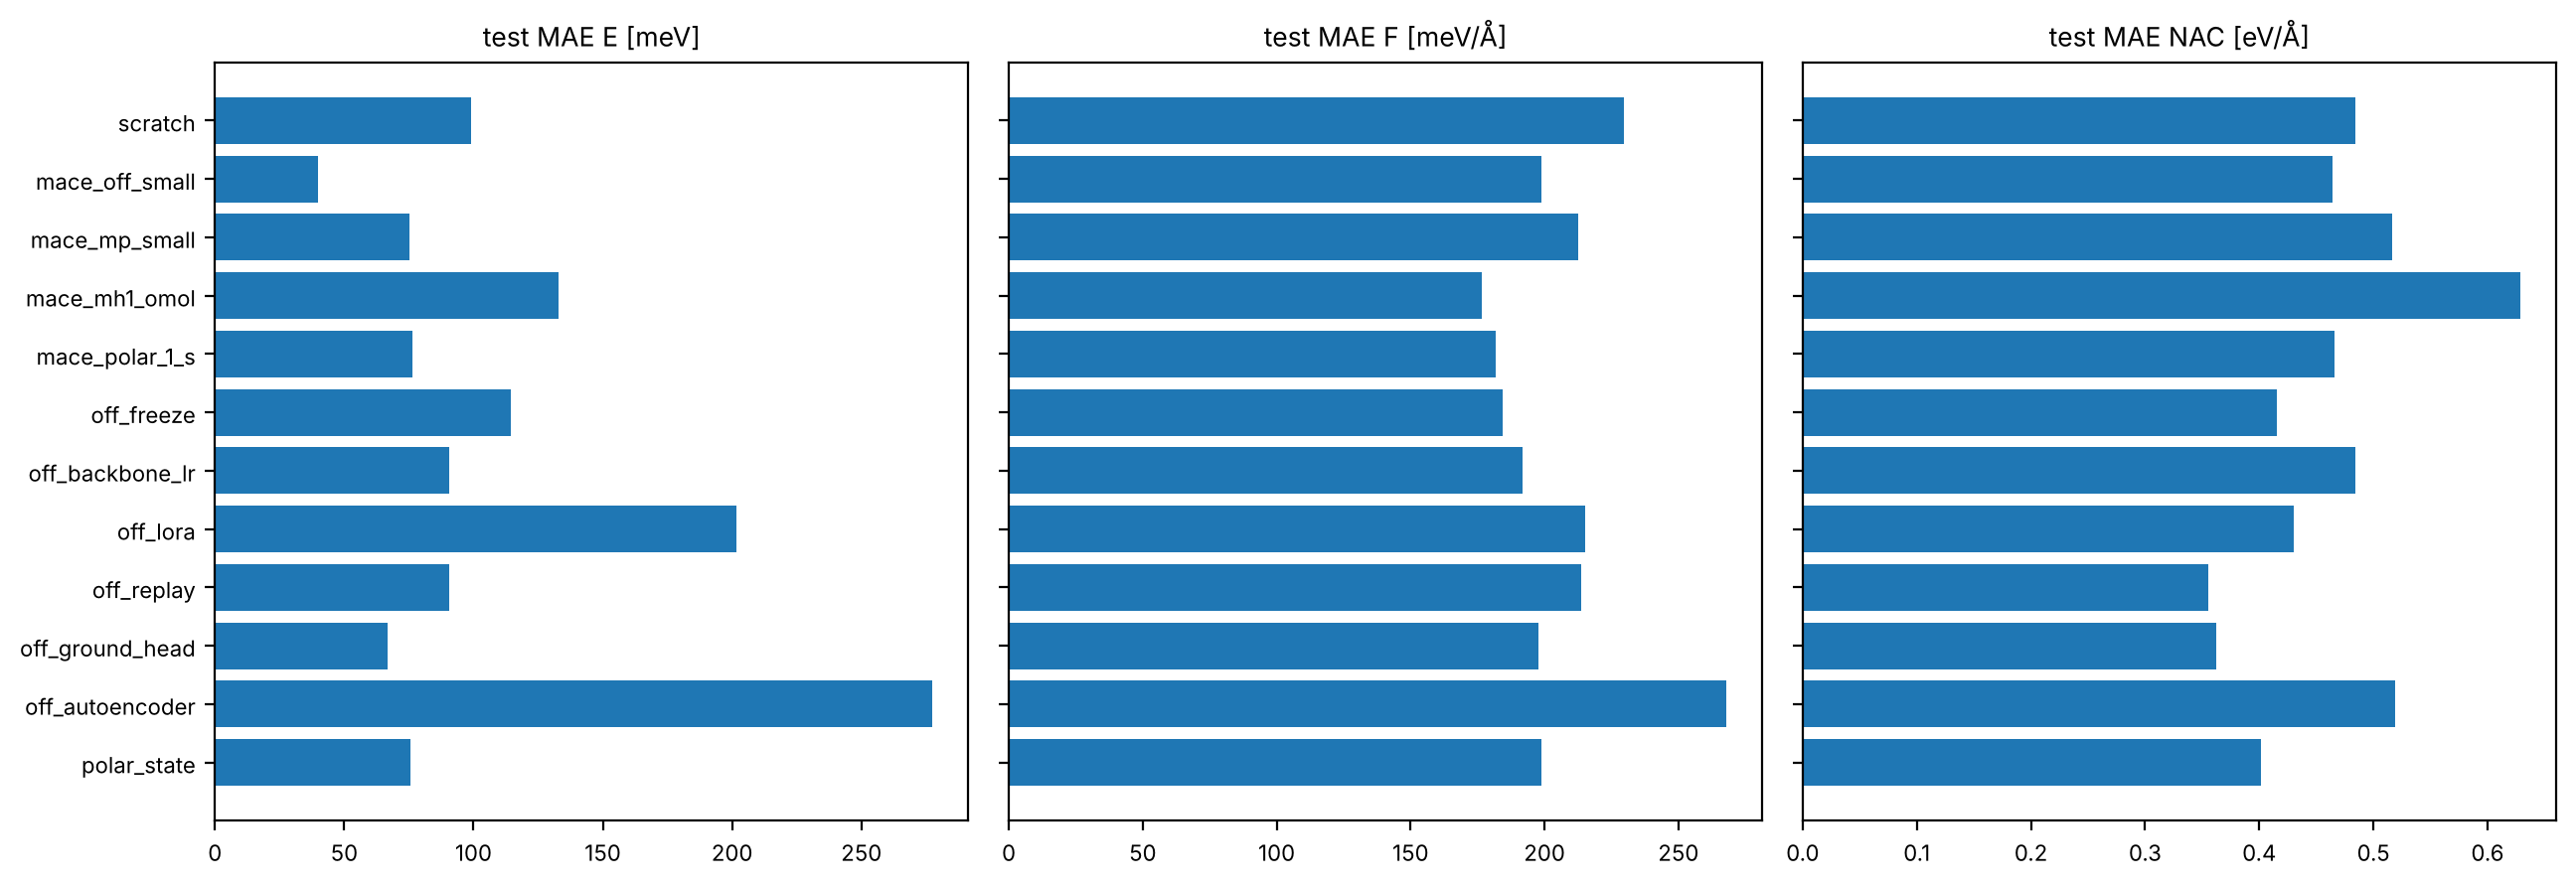

In [15]:
import re

import matplotlib.pyplot as plt

from mace.calculators import ExcitedMACECalculator
from mace.data.excited import soc_matrix_from_label
from mace.modules.spin_states import (
    same_multiplicity_pairs,
    soc_matrix_from_vectors,
    soc_vectors_from_matrix,
)

STATES = [4, 0, 3]
PAIRS = same_multiplicity_pairs(STATES)
UPPER = np.triu_indices(13, k=1)
test = ase.io.read(WORK / "so2_test.xyz", ":")


def test_errors(model_path, head=None):
    calc = ExcitedMACECalculator(str(model_path), device=os.environ["DEVICE"], head=head)
    err = {k: [] for k in ("E", "F", "NAC", "SOC", "dip")}
    for atoms in test:
        out = calc.predict(atoms)
        e_ref = atoms.info["REF_energy"]
        err["E"].append(np.abs(out["energies"] - e_ref).mean() * 1000)
        err["F"].append(np.abs(out["forces_states"] - atoms.info["REF_forces"]).mean() * 1000)
        gaps = np.array([abs(e_ref[j] - e_ref[i]) for i, j in PAIRS])
        n_ref = atoms.info["REF_nacs"] * gaps[None, :, None]
        dot = np.sum(n_ref * out["smooth_nacs"], axis=(0, 2))
        err["NAC"].append(np.abs(n_ref - out["smooth_nacs"] * np.where(dot < 0, -1, 1)[None, :, None]).mean())
        m_ref = soc_matrix_from_label(atoms.info["REF_socs"], STATES)
        v_ref, _ = soc_vectors_from_matrix(m_ref, STATES)
        v = out["soc_vectors"] * np.where(np.sum(v_ref * out["soc_vectors"], 1) < 0, -1, 1)[:, None]
        err["SOC"].append(np.abs(soc_matrix_from_vectors(v, STATES)[UPPER] - m_ref[UPPER]).mean())
        d_ref, d = atoms.info["REF_dipoles"], out["dipoles"].copy()
        d[7:] *= np.where(np.sum(d_ref[7:] * d[7:], 1) < 0, -1, 1)[:, None]
        err["dip"].append(np.abs(d - d_ref).mean())
    return {k: float(np.mean(v)) for k, v in err.items()}


runs = ["scratch", "mace_off_small", "mace_mp_small", "mace_mh1_omol", "mace_polar_1_s",
        "off_freeze", "off_backbone_lr", "off_lora", "off_replay", "off_ground_head",
        "off_autoencoder", "polar_state"]
results = {}
for name in runs:
    log = (RUN / "logs" / f"{name}_run-1.log").read_text()
    trainable = re.findall(r"Parameters: \d+ in total, (\d+) trainable", log)
    trainable += re.findall(r"Model with LoRA has (\d+) trainable", log)
    head = "excited" if name == "off_ground_head" else None
    results[name] = {**test_errors(RUN / f"{name}.model", head=head),
                     "trainable": int(trainable[-1])}
print(f"{'run':>16} | {'E meV':>6} | {'F meV/Å':>7} | {'NAC':>5} | {'SOC':>5} | {'dip':>6} | trainable")
for name, r in results.items():
    print(f"{name:>16} | {r['E']:6.1f} | {r['F']:7.1f} | {r['NAC']:.3f} | {r['SOC']:5.2f} | "
          f"{r['dip']:.4f} | {r['trainable']:>9}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, key, unit in zip(axes, ("E", "F", "NAC"), ("meV", "meV/Å", "eV/Å")):
    ax.barh(list(results), [results[n][key] for n in results], color="tab:blue")
    ax.set(title=f"test MAE {key} [{unit}]")
    ax.invert_yaxis()
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.tight_layout()
plt.show()

How to read this (15 epochs on 120 frames of an LVC model, so a guide, not a
ranking to quote):

* Starting from a molecular foundation lowers the energy and force errors of the
  model trained from scratch; the couplings are new in every model, so they improve
  less.
* Large foundations (MH-1, POLAR-1, OMOL) need a smaller learning rate than small
  ones; tune it per foundation instead of reusing one.
* Freezing, a smaller backbone learning rate and LoRA keep the backbone near the
  foundation: the ground-state energies move less, the trainable capacity goes into
  the readouts. Useful with few data or data covering a narrow region.
* Replay and extra ground-state heads train the shared backbone on more
  geometries; they help the couplings that are read from its features, and keep the
  ground state general for dynamics that leave the excited states.
* The autoencoder needs more epochs to settle than 15; compare it at convergence.

## 5. Fine-tuning a fine-tuned model on additional data

New reference calculations arrive. Pass your **trained X-MACE model** as
`--foundation_model`. X-MACE recognises an excited-state model and

* **continues** when this run's heads have the states and couplings of the model's
  heads (same name or `--foundation_head`) and the class is the same: every weight,
  shift and scale is kept, training simply goes on with the data you give;
* **transfers** otherwise: backbone and adapter keep their weights, the state
  readouts are new.

Continue on old + new data together, with a smaller learning rate, so the model does
not forget what it learned:

In [16]:
%%bash
cd work/foundations
mace_run_train \
    --name=continued \
    --foundation_model=mace_off_small.model \
    --train_file=small_plus_extra.xyz \
    --valid_fraction=0.15 --test_file=../so2_test.xyz \
    --model=ExcitedMACE --states="4 0 3" \
    --compute_nacs --compute_socs --compute_dipoles \
    --E0s=average \
    --batch_size=10 --max_num_epochs=10 --lr=0.001 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --socs_weight=1 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > continued.out 2>&1
grep -o "Continuing from the excited-state foundation model.*" logs/continued_run-1.log | head -1
echo "before:"; grep -A5 "Error-table on TEST" logs/mace_off_small_run-1.log | tail -n 2 | head -n 1
echo "after: "; grep -A5 "Error-table on TEST" logs/continued_run-1.log | tail -n 2 | head -n 1

Continuing from the excited-state foundation model: every head keeps all weights of its source head 

(Default <- Default), shifts and scales included


before:
| Default_Default_Default |       39.9  |          13.3      |        198.9    |       7.92 

 |       464.56     |      6690.60     |          32.48      |


after: 


| Default_Default_Default |       39.0  |          13.0      |        145.4    |       5.79  |      

 386.70     |      5603.94     |          26.85      |


Every option of section 4 works here too: add `--lora=True`, `--freeze=N` or
`--lr_params_factors=...`. Multi-head models continue head by head (same names).

**Transfer to new states.** The new calculations only have the 4 singlets with NACs
and dipoles. The layout differs, so X-MACE transfers backbone and adapter from the
trained model and builds new readouts; LoRA keeps the backbone close to it.

In [17]:
%%bash
cd work/foundations
mace_run_train \
    --name=singlets \
    --foundation_model=continued.model \
    --train_file=singlets.xyz --valid_fraction=0.15 \
    --model=ExcitedMACE --n_energies=4 \
    --compute_nacs --compute_dipoles \
    --lora=True --lora_rank=4 \
    --E0s=average \
    --batch_size=10 --max_num_epochs=10 --lr=0.005 --seed=1 \
    --energy_weight=10 --forces_weight=100 --nacs_weight=10 --dipoles_weight=1 \
    --device=$DEVICE --default_dtype=float64 \
    > singlets.out 2>&1
grep -o "Transfer from the excited-state foundation model.*" logs/singlets_run-1.log | cut -c1-120 | head -1
grep -A5 "Error-table on TRAIN" logs/singlets_run-1.log | tail -n 3

Transfer from the excited-state foundation model (the heads differ from the foundation's (states, co

uplings or names)): 


+---------------+-------------+--------------------+-----------------+-------------+----------------

--+------------------+---------------------+
| train_Default |       25.9  |           8.6      |   

      96.1    |       4.00  |       404.05     |       N/A        |          27.15      |
| valid_De

fault |       27.3  |           9.1      |        120.6    |       4.85  |       402.41     |       

N/A        |          28.59      |


## 6. The same commands on GPUs and clusters

Every command above runs on a GPU with `--device=cuda` (and usually
`--default_dtype=float32` for training speed). On several GPUs, start one process
per GPU; `--batch_size` is then per GPU:

```bash
torchrun --standalone --nproc_per_node=4 -m mace.cli.run_train \
    --distributed --launcher=torchrun --device=cuda \
    --name=mace_off_small --foundation_model=small_off ...   # the rest as above
```

With SLURM (one task per GPU):

```bash
#!/bin/bash
#SBATCH --nodes=1 --ntasks-per-node=4 --gpus-per-node=4 --cpus-per-task=8 --time=12:00:00
export MASTER_ADDR=$(scontrol show hostnames "$SLURM_JOB_NODELIST" | head -n 1)
export MASTER_PORT=29500
srun python -m mace.cli.run_train --distributed --launcher=slurm --device=cuda \
    --name=mace_off_small --foundation_model=small_off ...   # the rest as above
```

Long runs: add `--restart_latest` so a resubmitted job continues from its last
checkpoint.

## Summary

* `--foundation_model=<name or file>` puts any MACE foundation under an excited-state
  model; the architecture options then come from the foundation.
* Fine-tuning strategies are flags: `--freeze`, `--lr_params_factors`, `--lora`,
  `--multiheads_finetuning` with `--pt_train_file` and `--pseudolabel_replay`, extra
  heads via `--heads` or a YAML `--config`.
* A trained X-MACE model is itself a foundation: same heads → it continues with all
  weights; new states → backbone and adapter are transferred.
* All commands of this tutorial are in `04_commands.sh`.

**Next:** [Tutorial 5](05_using_a_trained_model.ipynb) uses a trained model: the ASE
calculator, scans, symmetry checks and what SHARC receives.